# Quantum Computing Lab 2: Quantum Circuit Simulator

## Introduction
Welcome to the lab 2 on Quantum Single and Multi Qubit Gates. Please follow the instructions and complete the exercises provided.

Install the packages once with `%pip install -r requirements.txt`, then restart the kernel. Keep `requirements.txt` in the same folder as this notebook. Python 3.11 or newer is required.

See [lab2_2026_cheatsheet.html](lab2_2026_cheatsheet.html) for useful functions and syntax.

In [300]:
# install requirements from lab2_requirements.txt
%pip install -r "lab2_requirements.txt"

Note: you may need to restart the kernel to use updated packages.


In [301]:
import numpy as np

## Part 1 - Prerequisites

### 1: Python/Numpy Recap

In [302]:
# TODO: Create a variable named 'complex_var' with the complex value 3 + 4j
complex_var = 3 + 4j

# TODO: Create a numpy array named 'array_var' with values 1, 2, 3, 4
array_var = np.array([1, 2, 3, 4])

# TODO: Create a 2x2 numpy matrix named 'real_matrix' with real values:
# [[1, 2], 
#  [3, 4]]
real_matrix = np.array([[1, 2], [3, 4]])

# TODO: Create a 2x2 numpy matrix named 'complex_matrix' with complex values:
# [[1 + 1j, 2 + 2j], 
#  [3 + 3j, 4 + 4j]]
complex_matrix = np.array([[1 + 1j, 2 + 2j], [3 + 3j, 4 + 4j]])

# TODO: Add 'real_matrix' and 'complex_matrix' and store the result in 'result_matrix'
result_matrix = real_matrix + complex_matrix

# TODO: Create a variable named 'angle' with the value of pi/2. Use numpy to get the value of pi.
angle = np.pi / 2

# TODO: Check whether 'angle' is approximately equal to 1.5708 (hint: use numpy's 'isclose' function)
# Store the result in 'is_approx_equal'
is_approx_equal = np.isclose(angle, 1.5708)

In [303]:
assert complex_var == 3 + 4j
assert np.array_equal(array_var, np.array([1, 2, 3, 4]))
assert np.array_equal(real_matrix, np.array([[1, 2], [3, 4]]))
assert np.array_equal(complex_matrix, np.array([[1 + 1j, 2 + 2j], [3 + 3j, 4 + 4j]]))
assert np.array_equal(result_matrix, np.array([[2 + 1j, 4 + 2j], [6 + 3j, 8 + 4j]]))
assert np.isclose(angle, np.pi / 2)
assert is_approx_equal


### 2: Check Quantum State Validity

Write a function that checks whether a given quantum state is valid (returns boolean).

In [304]:
def is_valid_state(state):
    return np.isclose(np.sum(np.abs(state) ** 2), 1.0)

In [305]:
state1 = np.array([0.6, 0.8])
state2 = np.array([0.5, 0.5])
state3 = np.array([0.70710678, 0.70710678])
state4 = np.array([0.5+0.5j, 0.5-0.5j])
state5 = np.array([1, 0])
assert is_valid_state(state1)
assert not is_valid_state(state2)
assert is_valid_state(state3)
assert is_valid_state(state4)
assert is_valid_state(state5)

### 3. X (Pauli-X or NOT gate)

Write a function that returns an X gate.

In [306]:
def X_gate():
    return np.array([[0, 1], [1, 0]], dtype=complex)

### 4. Y (Pauli-Y gate)

Write a function that returns an Y gate.

In [307]:
def Y_gate():
    return np.array([[0, -1j], [1j, 0]], dtype=complex)

### 5. Z (Pauli-Z gate)

Write a function that returns an Z gate.

In [308]:
def Z_gate():
    return np.array([[1, 0], [0, -1]], dtype=complex)

### 6. H (Hadamard gate)

Write a function that returns an H gate.

In [309]:
def H_gate():
    return np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)


### 7. S (Phase gate)

Write a function that returns an S gate.

In [310]:
def S_gate():
    return np.array([[1, 0], [0, 1j]], dtype=complex)

### 8. T (π/4 Phase gate)

Write a function that returns a T gate.

In [311]:
def T_gate():
    return np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]], dtype=complex)

In [312]:
gate1 = np.array([[0, 1], [1, 0]])
gate2 = np.array([[0.5, 0.5], [0.5, 0.5]])
gate3 = np.array([[0, -1j], [1j, 0]])
gate4 = np.array([[1, 0], [0, -1]])
gate5 = np.array([[0.70710678, 0.70710678], [0.70710678, -0.70710678]])
assert np.allclose(X_gate(), gate1)
assert np.allclose(Y_gate(), gate3)
assert np.allclose(Z_gate(), gate4)
assert np.allclose(H_gate(), gate5)
assert np.allclose(S_gate(), np.array([[1, 0], [0, 1j]]))
assert np.allclose(T_gate(), np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]]))

### 9. Compute Determinant

Write a function that computes the determinant of a given gate.

In [313]:
def compute_determinant(gate):
    return np.linalg.det(gate)


In [314]:
gate1 = np.array([[0, 1], [1, 0]])
gate2 = np.array([[0.5, 0.5], [0.5, 0.5]])
gate3 = np.array([[0, -1j], [1j, 0]])
gate4 = np.array([[1, 0], [0, -1]])
gate5 = np.array([[0.70710678, 0.70710678], [0.70710678, -0.70710678]])
matrix6 = np.array([[5, 4], [3, 7]])
assert np.allclose(compute_determinant(gate1), -1)
assert np.allclose(compute_determinant(gate2), 0)
assert np.allclose(compute_determinant(gate3), -1)
assert np.allclose(compute_determinant(gate4), -1)
assert np.allclose(compute_determinant(gate5), -1)
assert np.allclose(compute_determinant(matrix6), 23)

### 10. Given a quantum gate, compute its transpose

Write a function that computes the transpose of a matrix.

In [315]:
def compute_transpose(matrix):
    return np.transpose(matrix)


In [316]:
matrix1 = np.array([[1, 2], [3, 4]])
assert np.array_equal(compute_transpose(matrix1), np.array([[1, 3], [2, 4]]))
matrix2 = np.array([[1+1j, 2-1j], [3-1j, 4+1j]])
assert np.array_equal(compute_transpose(matrix2), np.array([[1+1j, 3-1j], [2-1j, 4+1j]]))
matrix3 = np.array([[1], [2], [3]])
assert np.array_equal(compute_transpose(matrix3), np.array([[1, 2, 3]]))
matrix4 = np.array([[1+1j], [2-2j], [3]])
assert np.array_equal(compute_transpose(matrix4), np.array([[1+1j, 2-2j, 3]]))
matrix5 = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
assert np.array_equal(compute_transpose(matrix5), np.array([[1, 4, 7], [2, 5, 8], [3, 6, 9]]))
matrix6 = np.array([[1+1j, 2-2j, 3+3j], [4-1j, 5+2j, 6-3j]])
assert np.array_equal(compute_transpose(matrix6), np.array([[1+1j, 4-1j], [2-2j, 5+2j], [3+3j, 6-3j]]))
matrix7 = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])
assert np.array_equal(compute_transpose(matrix7), np.array([[1, 5], [2, 6], [3, 7], [4, 8]]))


### 11. Given a quantum gate, compute its adjoint

Write a function that computes the adjoint of a matrix.

In [317]:
def compute_adjoint(matrix):
    return np.conjugate(np.transpose(matrix))


In [318]:
matrix1 = np.array([[1, 2], [3, 4]])
assert np.array_equal(compute_adjoint(matrix1), np.array([[1, 3], [2, 4]]))
matrix2 = np.array([[1+1j, 2-1j], [3-1j, 4+1j]])
assert np.array_equal(compute_adjoint(matrix2), np.array([[1-1j, 3+1j], [2+1j, 4-1j]]))
matrix3 = np.array([[1], [2], [3]])
assert np.array_equal(compute_adjoint(matrix3), np.array([[1, 2, 3]]))
matrix4 = np.array([[1+1j], [2-2j], [3]])
assert np.array_equal(compute_adjoint(matrix4), np.array([[1-1j, 2+2j, 3]]))
matrix5 = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
assert np.array_equal(compute_adjoint(matrix5), np.array([[1, 4, 7], [2, 5, 8], [3, 6, 9]]))
matrix6 = np.array([[1+1j, 2-2j, 3+3j], [4-1j, 5+2j, 6-3j]])
assert np.array_equal(compute_adjoint(matrix6), np.array([[1-1j, 4+1j], [2+2j, 5-2j], [3-3j, 6+3j]]))
matrix7 = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])
assert np.array_equal(compute_adjoint(matrix7), np.array([[1, 5], [2, 6], [3, 7], [4, 8]]))

### 12. Given a list of quantum gates, compute their sum

Write a function that receives a np array of matrices and computes their sum.

In [319]:
def add_gates(gate_list):
    return np.sum(gate_list, axis=0)


In [320]:
gate1 = np.array([[1, 2], [3, 4]])
gate2 = np.array([[4, 3], [2, 1]])
gate3 = np.array([[1+1j, 2-1j], [2+1j, 1-1j]])
gate4 = np.array([[0, 1j], [-1j, 0]])
gate5 = np.array([[1, 0], [0, 1]])

assert np.array_equal(add_gates([gate1, gate2]), np.array([[5, 5], [5, 5]]))
assert np.array_equal(add_gates([gate1, gate3]), np.array([[2+1j, 4-1j], [5+1j, 5-1j]]))
assert np.array_equal(add_gates([gate3, gate4]), np.array([[1+1j, 2], [2, 1-1j]]))
assert np.array_equal(add_gates([gate1, gate4, gate5]), np.array([[2, 2+1j], [3-1j, 5]]))
assert np.array_equal(add_gates([gate2, gate5]), np.array([[5, 3], [2, 2]]))


### 13. Given a list of quantum gates, compute their product

Write a function that receives a np array of matrices and computes their product.

In [321]:
def multiply_gates(gates):
    return np.linalg.multi_dot(gates)

In [322]:
gate1 = np.array([[1, 2], [3, 4]])
gate2 = np.array([[4, 3], [2, 1]])
gate3 = np.array([[1+1j, 2-1j], [2+1j, 1-1j]])
gate4 = np.array([[0, 1j], [-1j, 0]])
gate5 = np.array([[1, 0], [0, 1]])
assert np.array_equal(multiply_gates([gate1, gate2]), np.array([[8, 5], [20, 13]]))
assert np.array_equal(multiply_gates([gate1, gate3]), np.array([[5+3j, 4-3j], [11+7j, 10-7j]]))
assert np.array_equal(multiply_gates([gate3, gate4]), np.array([[-1-2j, -1+1j], [-1-1j, -1+2j]]))
assert np.array_equal(multiply_gates([gate1, gate4, gate5]), np.array([[-2j, 1j], [-4j, 3j]]))
assert np.array_equal(multiply_gates([gate2, gate5, gate3]), np.array([[10+7j, 11-7j], [4+3j, 5-3j]]))


### 14. Given a matrix and a constant, multiply them

Write a function that receives a matrix and a constant and computes their product.

In [323]:
def multiply_constant(matrix, constant):
    return matrix * constant


In [324]:
matrix1 = np.array([[1, 2], [3, 4]])
matrix2 = np.array([[4, 3], [2, 1]])
matrix3 = np.array([[1+1j, 2-1j], [2+1j, 1-1j]])
matrix4 = np.array([[0, 1j], [-1j, 0]])

const1 = 2
const2 = -1
const3 = 1j
assert np.array_equal(multiply_constant(matrix1, const1), np.array([[2, 4], [6, 8]]))
assert np.array_equal(multiply_constant(matrix2, const2), np.array([[-4, -3], [-2, -1]]))
assert np.array_equal(multiply_constant(matrix3, const3), np.array([[-1+1j, 1+2j], [-1+2j, 1+1j]]))
assert np.array_equal(multiply_constant(matrix4, const1), np.array([[0, 2j], [-2j, 0]]))
assert np.array_equal(multiply_constant(matrix1, const3), np.array([[1j, 2j], [3j, 4j]]))


### 15. Given a matrix, compute its rank.

Write a function that computes the rank of a matrix.

In [325]:
def compute_rank(matrix):
    return np.linalg.matrix_rank(matrix)


In [326]:
matrix1 = np.array([[1, 2, 3], [0, 1, 4], [0, 0, 0]])
matrix2 = np.array([[2, 3], [4, 6]])
matrix3 = np.array([[1+1j, 2-1j], [2+1j, 1-1j]])
matrix4 = np.array([[0, 1j], [-1j, 0]])
matrix5 = np.array([[1, 2], [3, 6]])

assert compute_rank(matrix1) == 2
assert compute_rank(matrix2) == 1
assert compute_rank(matrix3) == 2
assert compute_rank(matrix4) == 2
assert compute_rank(matrix5) == 1


### 16. Check Quantum Gate Validity

Write a function that checks whether a gate is valid (returns boolean).

In [327]:
def is_valid_gate(gate):
    return np.allclose(np.dot(gate, np.conjugate(np.transpose(gate))), np.eye(gate.shape[0]))

In [328]:
gate1 = np.array([[0, 1], [1, 0]])
gate2 = np.array([[0.5, 0.5], [0.5, 0.5]])
gate3 = np.array([[0, -1j], [1j, 0]])
gate4 = np.array([[1, 0], [0, -1]])
gate5 = np.array([[0.70710678, 0.70710678], [0.70710678, -0.70710678]])
matrix6 = np.array([[5, 4], [3, 7]])
assert is_valid_gate(gate1)
assert not is_valid_gate(gate2)
assert is_valid_gate(gate3)
assert is_valid_gate(gate4)
assert is_valid_gate(gate5)
assert not is_valid_gate(matrix6)

### 17. Compute Eigenvalues and Eigenvectors

Write a function that computes the eigenvalues and eigenvectors of a given matrix.

In [329]:
def get_eigen(gate):
    eigenvalues, eigenvectors = np.linalg.eig(gate)
    return eigenvalues, eigenvectors


In [330]:
gate1 = np.array([[2, 0], [0, 3]])
gate2 = np.array([[1, -1], [1, 1]])
gate3 = np.array([[0, -1j], [1j, 0]])
gate4 = np.array([[2, 1], [1, 2]])
gate5 = np.array([[3, 2], [0, 1]])

eigenvalues1, eigenvectors1 = get_eigen(gate1)
eigenvalues2, eigenvectors2 = get_eigen(gate2)
eigenvalues3, eigenvectors3 = get_eigen(gate3)
eigenvalues4, eigenvectors4 = get_eigen(gate4)
eigenvalues5, eigenvectors5 = get_eigen(gate5)

assert np.allclose(eigenvalues1, [2, 3]) or np.allclose(eigenvalues1[::-1], [2, 3])
assert np.allclose(eigenvalues2, [1+1j, 1-1j]) or np.allclose(eigenvalues2[::-1], [1+1j, 1-1j])
assert np.allclose(eigenvalues3, [1, -1]) or np.allclose(eigenvalues3[::-1], [1, -1])
assert np.allclose(eigenvalues4, [3, 1]) or np.allclose(eigenvalues4[::-1], [3, 1])
assert np.allclose(eigenvalues5, [3, 1]) or np.allclose(eigenvalues5[::-1], [3, 1])

assert np.allclose(np.dot(gate1, eigenvectors1[:, 0]), eigenvalues1[0] * eigenvectors1[:, 0])
assert np.allclose(np.dot(gate2, eigenvectors2[:, 1]), eigenvalues2[1] * eigenvectors2[:, 1])
assert np.allclose(np.dot(gate3, eigenvectors3[:, 0]), eigenvalues3[0] * eigenvectors3[:, 0])
assert np.allclose(np.dot(gate4, eigenvectors4[:, 1]), eigenvalues4[1] * eigenvectors4[:, 1])
assert np.allclose(np.dot(gate5, eigenvectors5[:, 0]), eigenvalues5[0] * eigenvectors5[:, 0])


### 18. Convert from Computational to +/- Basis

Write a function that receives a state in computational basis and returns the state converted to +/- basis.

In [331]:
def computational_to_plus_minus(state):
    return np.array([(state[0] + state[1]) / np.sqrt(2), (state[0] - state[1]) / np.sqrt(2)])


In [332]:
state_in_computational = np.array([0.70710678, 0.70710678])
state_in_plus_minus = np.array([1, 0])
assert np.allclose(computational_to_plus_minus(state_in_computational), state_in_plus_minus)

### 19. Convert from +/- to Computational Basis

Write a function that receives a state in +/- basis and returns the state converted to computational basis.

In [333]:
def plus_minus_to_computational(state):
    return np.array([(state[0] + state[1]) / np.sqrt(2), (state[0] - state[1]) / np.sqrt(2)])


In [334]:
state_in_computational = np.array([0.70710678, 0.70710678])
state_in_plus_minus = np.array([1, 0])
assert np.allclose(plus_minus_to_computational(state_in_plus_minus), state_in_computational)

### 20. Apply SQG to State

Write a function that receives a state and a gate and returns the resulting state obtained by applying the gate.

In [335]:
def apply_gate(state, gate):
    return np.dot(gate, state)


In [336]:
state1 = np.array([0.6, 0.8])
gate1 = np.array([[0, 1], [1, 0]])
gate3 = np.array([[0, -1j], [1j, 0]])
assert np.allclose(apply_gate(state1, gate1), np.array([0.8, 0.6]))
assert np.allclose(apply_gate(state1, gate3), np.array([-0.8j, 0.6j]))

### 21. Measure in Computational Basis

Write a function that receives a state and measures it in computational basis. The function should return 0 or 1.

Collapse the input NumPy array in place to the measured state.

In [337]:
import random

def measure_computational(state):
    outcome = random.choices([0, 1], weights=[np.abs(state[0])**2, np.abs(state[1])**2])[0]
    state[:] = 0
    state[outcome] = 1
    return outcome

In [338]:
state1 = np.array([0.6, 0.8])
state10 = np.array([1, 0])
state01 = np.array([0, 1])
assert measure_computational(state1) in [0, 1]
assert measure_computational(state1) in [0, 1]
assert measure_computational(state1) in [0, 1]
assert measure_computational(state1) in [0, 1]
assert measure_computational(state1) in [0, 1]
assert measure_computational(state10) == 0
assert measure_computational(state01) == 1

### 22. Measure in +/- Basis

Write a function that receives a state (in computational basis) and measures it in +/- basis. The function should return '+' or '-'

Collapse the input NumPy array in place to the measured state, keeping its coordinates in computational basis. Use an array with floating-point or complex dtype.

In [339]:
def measure_plus_minus(state):
    plus_minus_state = np.array([(state[0] + state[1]) / np.sqrt(2), (state[0] - state[1]) / np.sqrt(2)])
    outcome = random.choices(["+", "-"],weights=np.abs(plus_minus_state) ** 2)[0]
    state[:] = np.array([1, 1 if outcome == "+" else -1]) / np.sqrt(2)
    return outcome

In [340]:
statepm10 = np.array([1/np.sqrt(2), 1/np.sqrt(2)])
statepm01 = np.array([1/np.sqrt(2), -1/np.sqrt(2)])
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm10) == '+'
assert measure_plus_minus(statepm01) == '-'

### Conclusion
Congrats on mastering single qubit gates! As we embark on quantum entanglement, just remember: the math might feel like trying to untangle earbuds from your pocket. Stay patient and untangled! 🎧

## Part 2 - Multi-Qubit Simulator

In [341]:
import numpy as np

In [342]:
def H_gate():
    return np.array([
        [1,  1],
        [1, -1],
    ], dtype=complex) / np.sqrt(2)


def X_gate():
    return np.array([
        [0, 1],
        [1, 0],
    ], dtype=complex)


def S_gate():
    return np.array([
        [1, 0],
        [0, 1j],
    ], dtype=complex)


def CNOT_gate():
    return np.array([
        [1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, 0, 1],
        [0, 0, 1, 0],
    ], dtype=complex)


def CNOT10_gate():
    return np.array([
        [1, 0, 0, 0],
        [0, 0, 0, 1],
        [0, 0, 1, 0],
        [0, 1, 0, 0],
    ], dtype=complex)


def CH_gate():
    s = 1 / np.sqrt(2)
    return np.array([
        [1, 0, 0,  0],
        [0, 1, 0,  0],
        [0, 0, s,  s],
        [0, 0, s, -s],
    ], dtype=complex)


def SWAP_gate():
    return np.array([
        [1, 0, 0, 0],
        [0, 0, 1, 0],
        [0, 1, 0, 0],
        [0, 0, 0, 1],
    ], dtype=complex)


def Toffoli_gate():
    gate = np.eye(8, dtype=complex)
    gate[6:8, 6:8] = np.array([
        [0, 1],
        [1, 0],
    ], dtype=complex)
    return gate

In [343]:
class State:
    def __init__(self, n_qubits):
        self.n_qubits = n_qubits
        self.state = np.zeros((2 ** n_qubits,), dtype=complex)

    def initialize_state(self, qubit_values):
        assert len(qubit_values) == self.n_qubits
        assert all(bit in (0, 1) for bit in qubit_values)

        index = 0
        for bit in qubit_values:
            index = 2 * index + bit
        self.state = np.zeros((2 ** self.n_qubits,), dtype=complex)
        self.state[index] = 1
        
    def apply_gate(self, gate, n_gate, starting_qubit):
        assert 0 <= starting_qubit
        assert starting_qubit + n_gate <= self.n_qubits
        assert gate.shape == (2 ** n_gate, 2 ** n_gate)

        left = np.eye(2 ** starting_qubit, dtype=complex)
        right = np.eye(2 ** (self.n_qubits - starting_qubit - n_gate), dtype=complex)
        full_gate = np.kron(np.kron(left, gate), right)
        self.state = np.dot(full_gate, self.state)

    def apply_H_gate(self, target_qubit):
        self.apply_gate(H_gate(), 1, target_qubit)
    
    def apply_X_gate(self, target_qubit):
        self.apply_gate(X_gate(), 1, target_qubit)
    
    def apply_S_gate(self, target_qubit):
        self.apply_gate(S_gate(), 1, target_qubit)

    def apply_CNOT_gate(self, target_qubit):
        self.apply_gate(CNOT_gate(), 2, target_qubit)

    def apply_CH_gate(self, target_qubit):
        self.apply_gate(CH_gate(), 2, target_qubit)
    
    def apply_SWAP_gate(self, target_qubit):
        self.apply_gate(SWAP_gate(), 2, target_qubit)
    
    def apply_CNOT10_gate(self, target_qubit):
        self.apply_gate(CNOT10_gate(), 2, target_qubit)
    
    def apply_TOFFOLI_gate(self, target_qubit):
        self.apply_gate(Toffoli_gate(), 3, target_qubit)
    
    def sample(self):
        probabilities = np.abs(self.state) ** 2
        index = np.random.choice(len(self.state), p=probabilities/probabilities.sum())
        bits = format(index, f"0{self.n_qubits}b")
        return np.array([int(bit) for bit in bits])

    def produce_measurement(self):
        measured_bits = self.sample()
        self.initialize_state(measured_bits)
        return measured_bits

In [348]:
qstate = State(5)
qstate.initialize_state([0,1,1,0,0])
print(qstate.state)
print(qstate.sample())
qstate.apply_H_gate(0)
qstate.apply_X_gate(1)
qstate.apply_CNOT10_gate(0)
print(qstate.sample())
print(qstate.sample())
print(qstate.sample())
print(qstate.sample())
print(qstate.sample())
print(qstate.sample())

[0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j
 0.+0.j 0.+0.j]
[0 1 1 0 0]
[0 0 1 0 0]
[0 0 1 0 0]
[1 0 1 0 0]
[1 0 1 0 0]
[1 0 1 0 0]
[1 0 1 0 0]


#### 2.1: Define state
Fill in the `__init__` function.

An n-qubit state is an array of 2^n coefficients (one for each possible value of the qubits).

Use complex coefficients. Qubit 0 is the leftmost bit in a basis label: `|q0 q1 ...>`. The initial state is `|00...0>`.

#### 2.2: Initialize state
Fill in the `initialize_state` function.

The function receives an array of desired value for each qubit, e.g. `[0,1,0,0]` for a 4-qubit system. The function should set the state accordingly.

#### 2.3: Apply a gate
Fill in the `apply_gate` function

This function generates the unitary matrix which applies the `gate` gate to the current `state`. The parameter `n_gate` represents the number of qubits affected by the gate (e.g. for a `H` gate it would be 1; for a `CNOT` gate it would be 2). The `starting_qubit` represents the first qubit affected by the gate.

Hint: `np.kron`


#### 2.4: Define single qubit gates
Fill in the functions to define the H, X, S gates.

Hint: use `apply_gate`

#### 2.5: Define multi qubit gates
Fill in the functions to define the CNOT, CH, SWAP, Toffoli gates. Hint: use `apply_gate`

The CNOT10 represents a reverse CNOT (i.e. first bit is the target and second is the control). Exercise: compute the 2-qubit matrix for CNOT10.


#### 2.6: Sample the state
Fill in the `sample` function.

The function should randomly sample according to state probabilities and output an array of qubit values (e.g. `[0,0,1,0]` for a 4-qubit system). DO NOT collapse the state.

#### 2.7: Measure the state
Fill in the `produce_measurement` function.

The function should randomly measure according to state probabilities and output an array of qubit values (e.g. `[0,0,1,0]` for a 4-qubit system). Collapse the state to the measured computational basis state. An immediate second measurement should return the same result.


In [ ]:
print(qstate.produce_measurement())
print(qstate.produce_measurement())

[1 0 1 0 0]
[1 0 1 0 0]


## Part 3 - Implement Circuit

### 3.1: Implement circuit in your simulator

Implement the following circuit using your code. 

Output the following:
 - the magnitude and probability for each output
 - the outputs of 10 random samples (without collapsing the stored state)


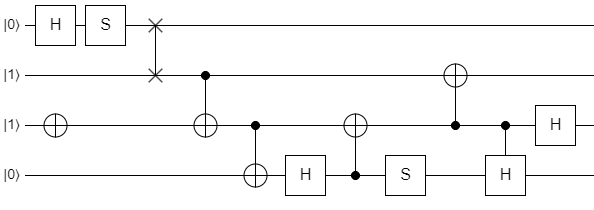

In [ ]:
circuit = State(4)
circuit.initialize_state([0, 1, 1, 0])

circuit.apply_H_gate(0)
circuit.apply_X_gate(2)
circuit.apply_S_gate(0)
circuit.apply_SWAP_gate(0)
circuit.apply_CNOT_gate(1)
circuit.apply_CNOT_gate(2)
circuit.apply_H_gate(3)
circuit.apply_CNOT10_gate(2)
circuit.apply_S_gate(3)
circuit.apply_CNOT10_gate(1)
circuit.apply_CH_gate(2)
circuit.apply_H_gate(2)

for index, amplitude in enumerate(circuit.state):
    output = format(index, f"0{circuit.n_qubits}b")
    magnitude = np.abs(amplitude)
    probability = magnitude ** 2

    print(
        f"|{output}>: value={amplitude:.5f}, "
        f"magnitude={magnitude:.4f}, "
        f"probability={probability:.4f} ({probability:.2%})"
    )

print("\n10 random samples:")
for _ in range(15):
    print(circuit.sample())


print("\nsamples after measurement:")
for _ in range(3):
    print(circuit.produce_measurement())

|0000>: value=0.00000+0.00000j, magnitude=0.0000, probability=0.0000 (0.00%)
|0001>: value=0.00000+0.00000j, magnitude=0.0000, probability=0.0000 (0.00%)
|0010>: value=0.00000+0.00000j, magnitude=0.0000, probability=0.0000 (0.00%)
|0011>: value=0.00000+0.00000j, magnitude=0.0000, probability=0.0000 (0.00%)
|0100>: value=0.00000+0.00000j, magnitude=0.0000, probability=0.0000 (0.00%)
|0101>: value=0.00000+0.00000j, magnitude=0.0000, probability=0.0000 (0.00%)
|0110>: value=0.00000+0.00000j, magnitude=0.0000, probability=0.0000 (0.00%)
|0111>: value=0.00000+0.00000j, magnitude=0.0000, probability=0.0000 (0.00%)
|1000>: value=0.35355+0.25000j, magnitude=0.4330, probability=0.1875 (18.75%)
|1001>: value=0.00000+0.25000j, magnitude=0.2500, probability=0.0625 (6.25%)
|1010>: value=0.35355-0.25000j, magnitude=0.4330, probability=0.1875 (18.75%)
|1011>: value=0.00000-0.25000j, magnitude=0.2500, probability=0.0625 (6.25%)
|1100>: value=0.00000+0.25000j, magnitude=0.2500, probability=0.0625 (6.25

### 3.2: Implement circuit in Quirk

Implement the same circuit in https://algassert.com/quirk and compare the results with your code.

Quirk treats the top wire as the least significant bit. Reverse its basis bitstrings when comparing with the `q0 q1 q2 q3` order used by our simulator.

In [347]:
https://algassert.com/quirk#circuit=%7B%22cols%22%3A%5B%5B%22H%22%2C1%2C%22X%22%5D%2C%5B%22Z%5E%C2%BD%22%5D%2C%5B%22Swap%22%2C%22Swap%22%5D%2C%5B1%2C%22%E2%80%A2%22%2C%22X%22%5D%2C%5B1%2C1%2C%22%E2%80%A2%22%2C%22X%22%5D%2C%5B1%2C1%2C1%2C%22H%22%5D%2C%5B1%2C1%2C%22X%22%2C%22%E2%80%A2%22%5D%2C%5B1%2C1%2C1%2C%22Z%5E%C2%BD%22%5D%2C%5B1%2C%22X%22%2C%22%E2%80%A2%22%5D%2C%5B1%2C1%2C%22%E2%80%A2%22%2C%22H%22%5D%2C%5B1%2C1%2C%22H%22%5D%5D%2C%22init%22%3A%5B0%2C1%2C1%5D%7D


{
  "cols": [
    [
      "H",
      1,
      "X"
    ],
    [
      "Z^½"
    ],
    [
      "Swap",
      "Swap"
    ],
    [
      1,
      "•",
      "X"
    ],
    [
      1,
      1,
      "•",
      "X"
    ],
    [
      1,
      1,
      1,
      "H"
    ],
    [
      1,
      1,
      "X",
      "•"
    ],
    [
      1,
      1,
      1,
      "Z^½"
    ],
    [
      1,
      "X",
      "•"
    ],
    [
      1,
      1,
      "•",
      "H"
    ],
    [
      1,
      1,
      "H"
    ]
  ],
  "init": [
    0,
    1,
    1
  ]
}

SyntaxError: invalid syntax (1504178068.py, line 1)

### 3.3: Implement circuit in IBM Qiskit

#### Qiskit local

Implement the same circuit using Qiskit, run it using the local Qiskit Aer simulator and compare the results with your code.

Use the packages from `requirements.txt`.

Hint: read the [QuantumCircuit documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit).


Statevector: [0.70710678+0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]


Matplotlib is building the font cache; this may take a moment.


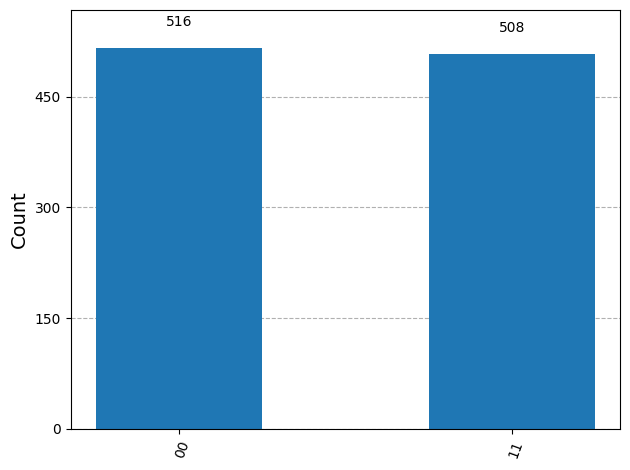

In [ ]:
# EXAMPLE QISKIT USAGE
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram

# Example circuit: 2-qubit Bell state
bell_qc = QuantumCircuit(2)
bell_qc.h(0)
bell_qc.cx(0, 1)

# Keep the original circuit without measurements for statevector calculations.
print("Statevector:", Statevector.from_instruction(bell_qc).data)
bell_measured = bell_qc.copy()
bell_measured.measure_all()

# Simulate the circuit
simulator = AerSimulator()
bell_compiled = transpile(bell_measured, simulator)
bell_result = simulator.run(bell_compiled, shots=1024, seed_simulator=2026).result()

# Get the results and plot
bell_counts = bell_result.get_counts()
plot_histogram(bell_counts)


Implement the four-qubit circuit from Part 3.1 below. Use the same wire numbers: the top wire is qubit 0. Do not add measurement gates yet.

Qiskit writes bitstrings in the order `q3 q2 q1 q0`, while our simulator uses `q0 q1 q2 q3`. The comparison cell reverses Qiskit's output ordering. This changes the displayed ordering, not the circuit.


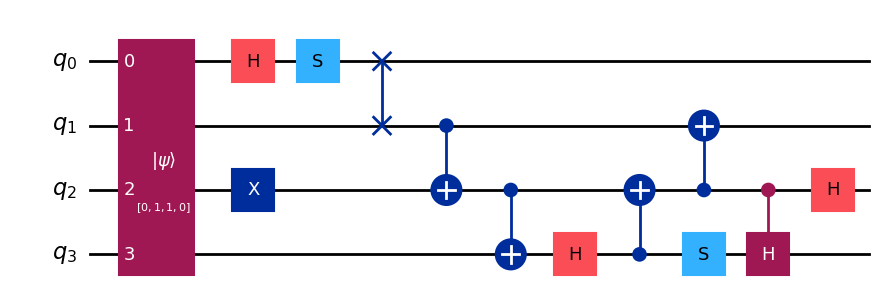

In [ ]:
qc = QuantumCircuit(4)

qc.initialize("0110", [0, 1, 2, 3])

qc.h(0)
qc.x(2)
qc.s(0)
qc.swap(0, 1)
qc.cx(1, 2)
qc.cx(2, 3)
qc.h(3)
qc.cx(3, 2)
qc.s(3)
qc.cx(2, 1)
qc.ch(2, 3)
qc.h(2)

qc.draw("mpl")


In [ ]:
# Exact amplitudes, in the same qubit order as our simulator.
qiskit_state = Statevector.from_instruction(qc).reverse_qargs().data
print("Amplitudes:\n", qiskit_state)
print("Probabilities:\n", np.abs(qiskit_state) ** 2)

# Sample repeated measurements of fresh copies of the circuit.
qc_measured = qc.copy()
qc_measured.measure_all()
qc_compiled = transpile(qc_measured, simulator)
result = simulator.run(qc_compiled, shots=1024, seed_simulator=2026).result()
counts = result.get_counts()
counts_lab_order = {bits[::-1]: count for bits, count in counts.items()}
plot_histogram(counts_lab_order)


print("\n\n\n")
print(np.allclose(circuit.state, qiskit_state)) # Dont produce measurement for True

Amplitudes:
 [0.        +0.j   0.        +0.j   0.        +0.j   0.        +0.j
 0.        +0.j   0.        +0.j   0.        +0.j   0.        +0.j
 0.35355339+0.25j 0.        +0.25j 0.35355339-0.25j 0.        -0.25j
 0.        +0.25j 0.35355339-0.25j 0.        -0.25j 0.35355339+0.25j]
Probabilities:
 [0.     0.     0.     0.     0.     0.     0.     0.     0.1875 0.0625
 0.1875 0.0625 0.0625 0.1875 0.0625 0.1875]




True


### 3.4: Run Qiskit on real quantum hardware

Run the same four-qubit circuit on a real IBM quantum device and compare the results with the ideal simulation.

Create an API key and select an instance at [IBM Quantum Platform](https://quantum.cloud.ibm.com/). Set the environment variables `IBM_QUANTUM_API_KEY` and `IBM_QUANTUM_INSTANCE_CRN` using that key and the instance CRN.

Set `RUN_ON_HARDWARE = True` only when you are ready to submit a real job to the selected instance. With the default `False`, this cell skips hardware execution. Keep your API key out of the submitted notebook.

[Account setup](https://quantum.cloud.ibm.com/docs/en/guides/initialize-account) · [Sampler documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/executor-sampler-sampler)


In [ ]:
# EXAMPLE IBM QUANTUM USAGE
RUN_ON_HARDWARE = False

if RUN_ON_HARDWARE:
    import os
    from qiskit_ibm_runtime import QiskitRuntimeService
    from qiskit_ibm_runtime.executor_sampler import Sampler
    from qiskit.transpiler import generate_preset_pass_manager
    from IPython.display import display

    api_key = os.environ.get("IBM_QUANTUM_API_KEY")
    instance_crn = os.environ.get("IBM_QUANTUM_INSTANCE_CRN")
    if not api_key or not instance_crn:
        raise ValueError("Set IBM_QUANTUM_API_KEY and IBM_QUANTUM_INSTANCE_CRN first.")

    service = QiskitRuntimeService(
        channel="ibm_quantum_platform", token=api_key, instance=instance_crn
    )
    backend = service.least_busy(
        operational=True, simulator=False, min_num_qubits=qc.num_qubits
    )
    print("Backend:", backend.name)

    # Compile the same measured circuit for the selected device.
    pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_qc = pass_manager.run(qc_measured)

    sampler = Sampler(mode=backend)
    job = sampler.run([isa_qc], shots=1024)
    print("Job ID:", job.job_id())
    hardware_counts = job.result()[0].data.meas.get_counts()
    hardware_counts_lab_order = {
        bits[::-1]: count for bits, count in hardware_counts.items()
    }
    display(plot_histogram(hardware_counts_lab_order))
else:
    print("Hardware execution skipped. Set RUN_ON_HARDWARE = True when ready.")


## Part 4 - Representation

### 23. Change to Polar Coordinates

Write a function that receives a state and computes its polar coordinates. The returaned outputs must be theta (the angle), phi (the phase), and omega (the global phase which can be ignored). 
Hint: https://quantumcomputing.stackexchange.com/questions/26431/can-i-convert-a-qubit-in-complex-form-to-polar-form

Use `0 <= theta <= pi` and phases in `[-pi, pi]`. At either pole, use `phi = 0` and take `omega` from the nonzero coefficient.

In [351]:
import cmath
import math

def to_polar(state):
    state = np.asarray(state, dtype=complex)
    if state.shape != (2,):
        raise ValueError("Max single qubit")
    if not np.all(np.isfinite(state)) or not np.isclose(np.linalg.norm(state), 1):
        raise ValueError("State not finite or normalized")

    alpha, beta = state

    if abs(beta) < 1e-12:
        return 0.0, 0.0, np.angle(alpha)

    if abs(alpha) < 1e-12:
        return np.pi, 0.0, np.angle(beta)

    theta = 2 * np.arctan2(abs(beta), abs(alpha))
    omega = np.angle(alpha)
    phi = np.angle(beta) - omega

    phi = (phi + np.pi) % (2 * np.pi) - np.pi

    return theta, phi, omega

In [352]:
# 1. Basic |0> state
state_1 = [1, 0]
expected_1 = (0, 0, 0)
result_1 = to_polar(state_1)
assert np.isclose(result_1, expected_1).all(), f"Expected {expected_1}, got {result_1}"

# 2. Basic |1> state
state_2 = [0, 1]
expected_2 = (np.pi, 0, 0)
result_2 = to_polar(state_2)
assert np.isclose(result_2, expected_2).all(), f"Expected {expected_2}, got {result_2}"

# 3. Equal superposition with no phase difference
state_3 = [np.sqrt(0.5), np.sqrt(0.5)]
expected_3 = (np.pi/2, 0, 0)
result_3 = to_polar(state_3)
assert np.isclose(result_3, expected_3).all(), f"Expected {expected_3}, got {result_3}"

# 4. Equal superposition with a phase difference
state_4 = [np.sqrt(0.5), np.sqrt(0.5) * np.exp(1j * np.pi/3)]
expected_4 = (np.pi/2, np.pi/3, 0)
result_4 = to_polar(state_4)
assert np.isclose(result_4, expected_4).all(), f"Expected {expected_4}, got {result_4}"

# 5. Complex coefficients
state_5 = [1/3 + 2j/3, 2/3 - 1j/3]
state_5 = np.array(state_5) / np.linalg.norm(state_5)
expected_5 = (np.pi/2, -np.pi/2, 1.1071487177940904)
result_5 = to_polar(state_5)
assert np.isclose(result_5, expected_5).all(), f"Expected {expected_5}, got {result_5}"

# 6. Another complex coefficient example
state_6 = [0.5 + 0.5j, 0.5 - 0.5j]
expected_6 = (np.pi/2, -np.pi/2, np.pi/4)
result_6 = to_polar(state_6)
assert np.isclose(result_6, expected_6).all(), f"Expected {expected_6}, got {result_6}"

# 7. Yet another complex coefficient case
state_7 = [0.6 + 0.8j, -0.8 + 0.6j]
state_7 = np.array(state_7) / np.linalg.norm(state_7)
expected_7 = (np.pi/2, np.pi/2, 0.9272952180016122)
result_7 = to_polar(state_7)
assert np.isclose(result_7, expected_7).all(), f"Expected {expected_7}, got {result_7}"

### 24. Represent the probabilities of measurement

Write a function that receives a state (in computational basis) and draws a bar chart to represent the probabilities of measurement in computational basis.

In [359]:
import matplotlib.pyplot as plt
import numpy as np

def plot_state_probabilities(state):
    probabilities = np.abs(state) ** 2
    n_qubits = int(np.log2(len(state)))
    labels = [format(i, f"0{n_qubits}b") for i in range(len(state))]

    plt.figure(figsize=(10, 4))
    plt.bar(labels, probabilities)
    plt.xlabel("Computational basis state")
    plt.ylabel("Probability")
    plt.ylim(0, 1)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

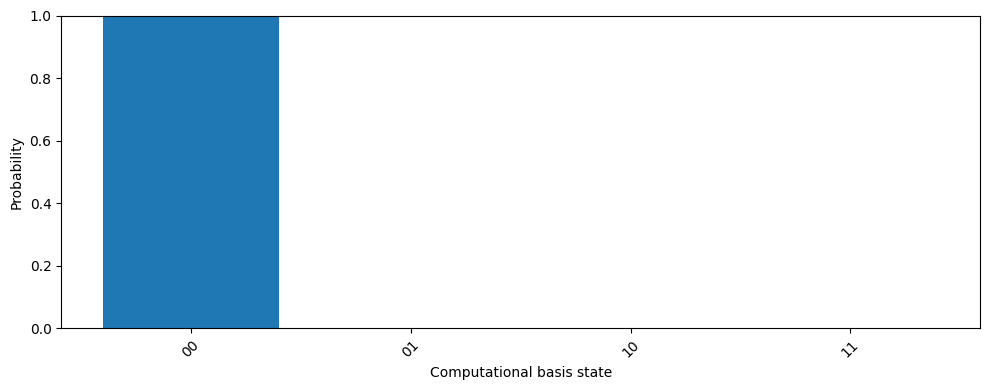

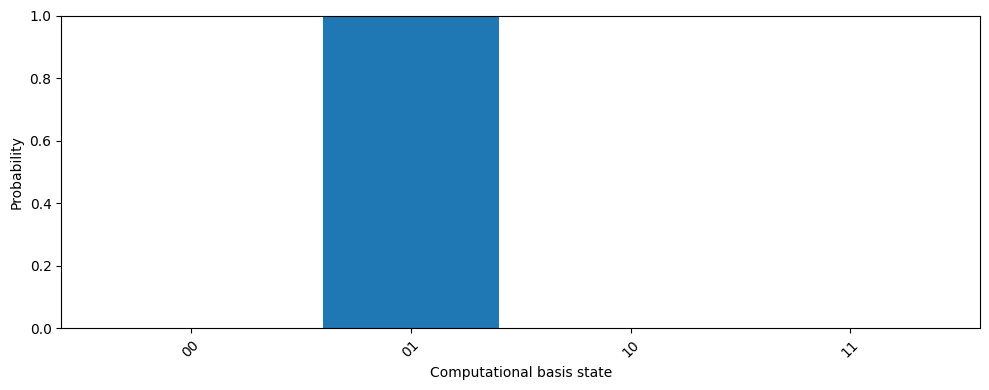

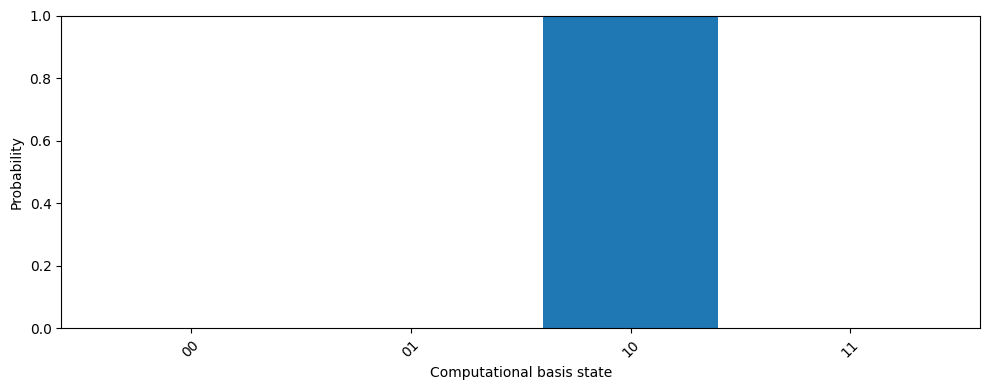

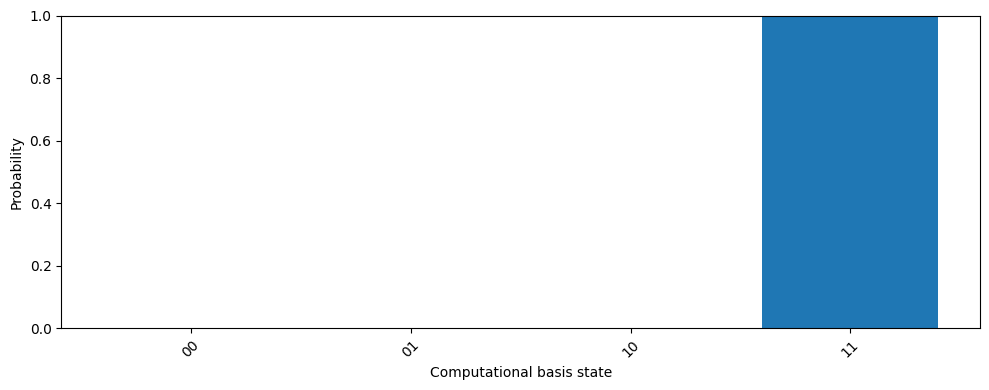

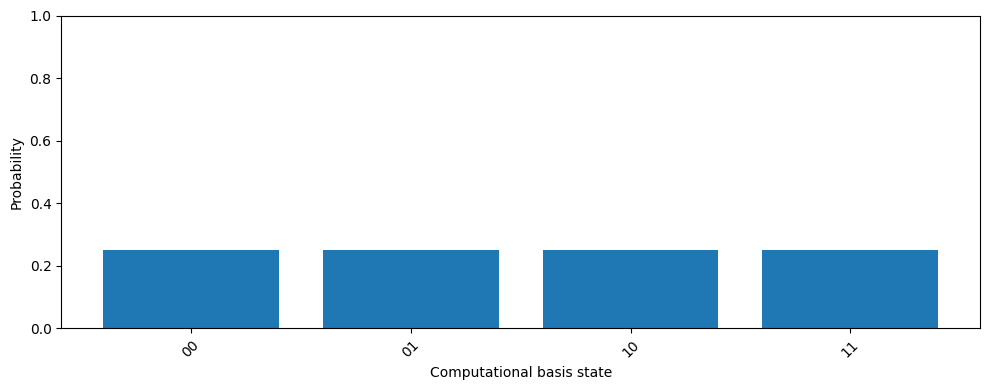

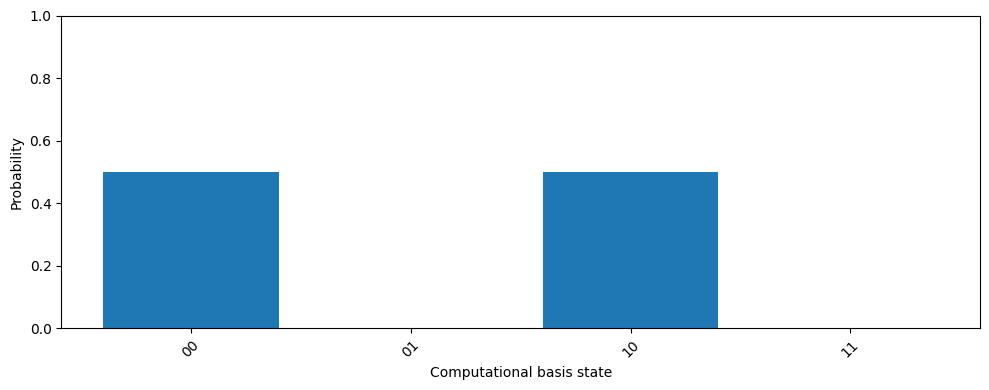

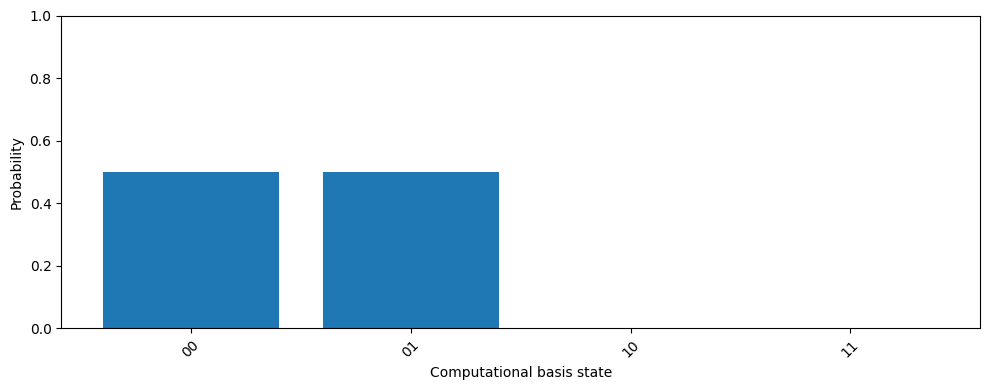

In [364]:
# TODO: test with some states

plot_state_probabilities(np.array([1, 0, 0, 0]))
plot_state_probabilities(np.array([0, 1, 0, 0]))
plot_state_probabilities(np.array([0, 0, 1, 0]))
plot_state_probabilities(np.array([0, 0, 0, 1]))
plot_state_probabilities(np.array([1/2, 1/2, 1/2, 1/2]))
plot_state_probabilities(np.array([1/np.sqrt(2), 0, 1/np.sqrt(2), 0]))
plot_state_probabilities(np.array([1/np.sqrt(2), 1/np.sqrt(2), 0, 0]))

### 25. Represent the Bloch sphere

Write a function that receives a state (in computational basis) and represents it as a Bloch sphere.

Use a normalized single-qubit pure state.

In [365]:
import matplotlib.pyplot as plt
import numpy as np

def plot_bloch_representation(state):
    theta, phi, _ = to_polar(state)

    x = np.sin(theta) * np.cos(phi)
    y = np.sin(theta) * np.sin(phi)
    z = np.cos(theta)

    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, projection="3d")

    # Sphere surface
    u = np.linspace(0, 2 * np.pi, 40)
    v = np.linspace(0, np.pi, 20)
    ax.plot_surface(
        np.outer(np.cos(u), np.sin(v)),
        np.outer(np.sin(u), np.sin(v)),
        np.outer(np.ones_like(u), np.cos(v)),
        color="lightblue",
        alpha=0.15,
    )

    # State vector
    ax.quiver(0, 0, 0, x, y, z, color="red", linewidth=2)
    ax.scatter(x, y, z, color="red")

    ax.text(0, 0, 1.15, "|0⟩")
    ax.text(0, 0, -1.15, "|1⟩")
    ax.set(
        xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1),
        xlabel="X", ylabel="Y", zlabel="Z",
        title="Bloch sphere",
    )
    ax.set_box_aspect((1, 1, 1))
    plt.show()

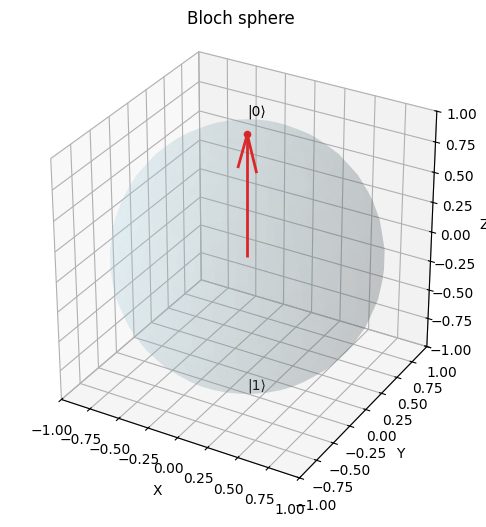

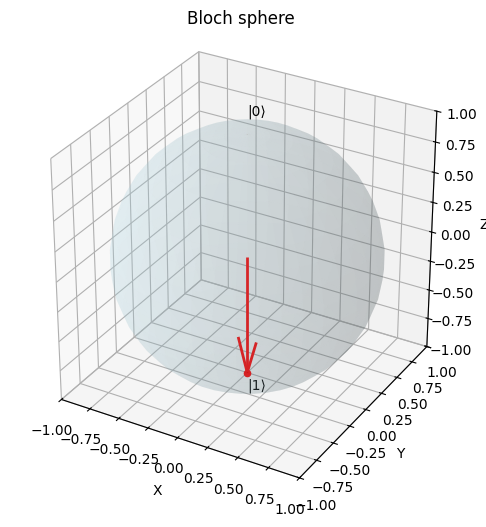

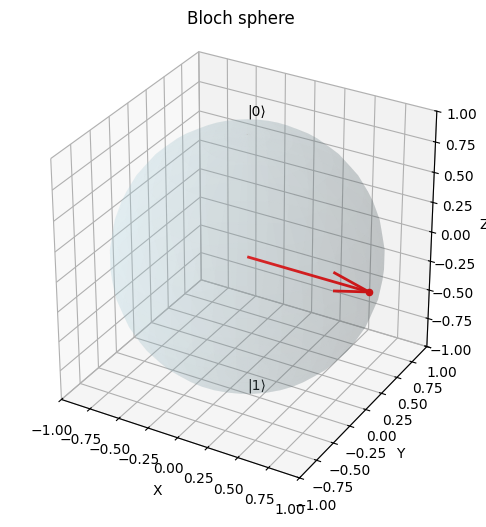

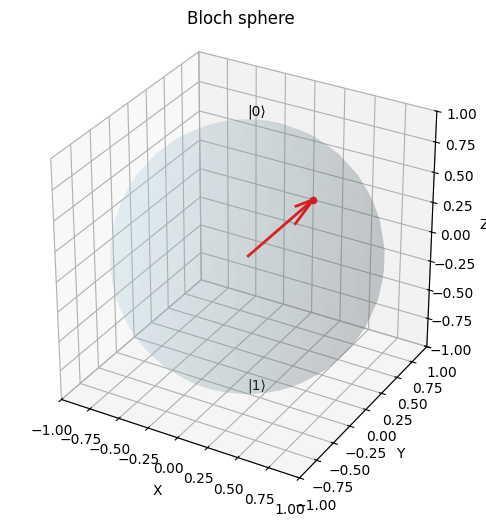

In [367]:
# TODO: test with some states


plot_bloch_representation(np.array([1, 0]))
plot_bloch_representation(np.array([0, 1]))
plot_bloch_representation(np.array([1/np.sqrt(2), 1/np.sqrt(2)]))
plot_bloch_representation(np.array([1/np.sqrt(2), 1j/np.sqrt(2)]))

### 26. Represent eigenvalues and eigenvectors

Write a function that receives a gate and represents its eigenvectors. Suggestion: take random points on a plane (i.e. random vectors) and represent with lines or arrows the effect of the matrix on those vectors. The eigenvectors should change only by a constant factor, which is the eigenvalue.

For this 2D plot, use a gate with real entries and real eigenvectors, such as X, Z or H.

In [371]:
import matplotlib.pyplot as plt
import numpy as np

def plot_gate_representation(gate):
    gate = np.asarray(gate)

    if gate.shape != (2, 2) or not np.allclose(gate.imag, 0):
        raise ValueError("Use a real 2×2 gate")

    gate = gate.real
    eigenvalues, eigenvectors = np.linalg.eig(gate)

    if not np.allclose(eigenvalues.imag, 0):
        raise ValueError("The gate must have real eigenvectors and eigenvalues")

    rng = np.random.default_rng(42)
    vectors = rng.uniform(-1, 1, size=(20, 2))
    transformed = (gate @ vectors.T).T

    fig, ax = plt.subplots(figsize=(7, 7))

    ax.quiver(
        np.zeros(20), np.zeros(20),
        vectors[:, 0], vectors[:, 1],
        angles="xy", scale_units="xy", scale=1,
        color="gray", alpha=0.5, label="Original vectors",
    )
    ax.quiver(
        np.zeros(20), np.zeros(20),
        transformed[:, 0], transformed[:, 1],
        angles="xy", scale_units="xy", scale=1,
        color="blue", alpha=0.5, label="Transformed vectors",
    )

    limit = 1.2 * max(
        1, np.max(np.abs(vectors)), np.max(np.abs(transformed))
    )

    for i, color in enumerate(["red", "green"]):
        vector = eigenvectors[:, i].real
        eigenvalue = eigenvalues[i].real

        ax.plot(
            [-limit * vector[0], limit * vector[0]],
            [-limit * vector[1], limit * vector[1]],
            "--", color=color,
            label=f"Eigenvector direction, λ={eigenvalue:.2f}",
        )

    ax.axhline(0, color="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=0.5)
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit),
           xlabel="First coordinate", ylabel="Second coordinate")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

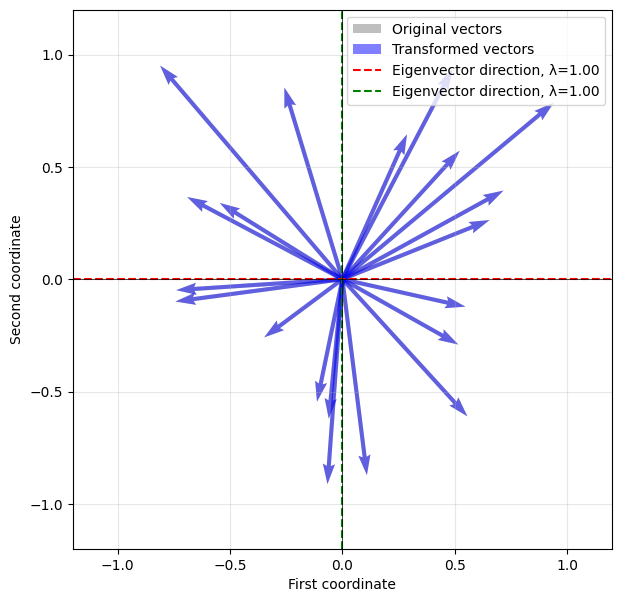

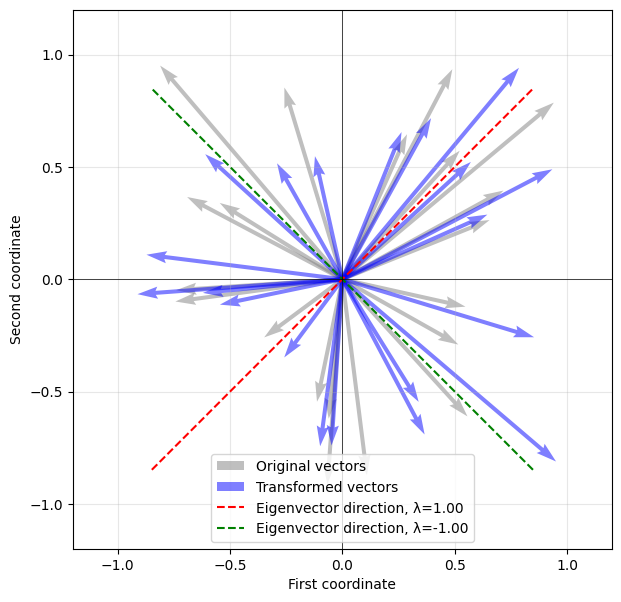

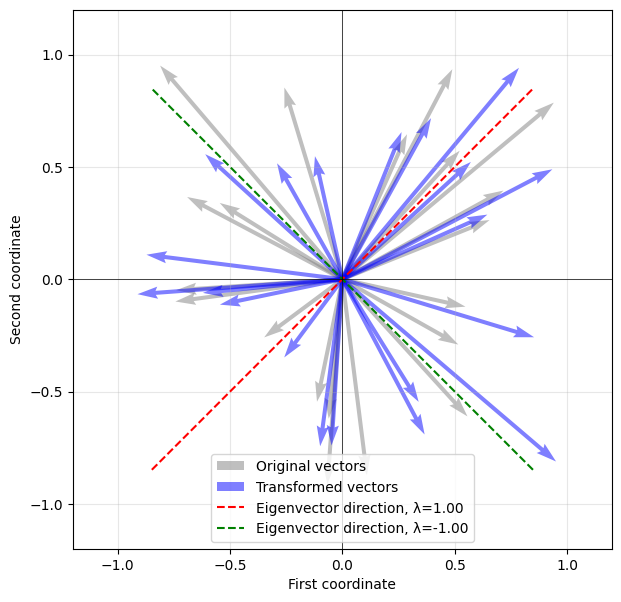

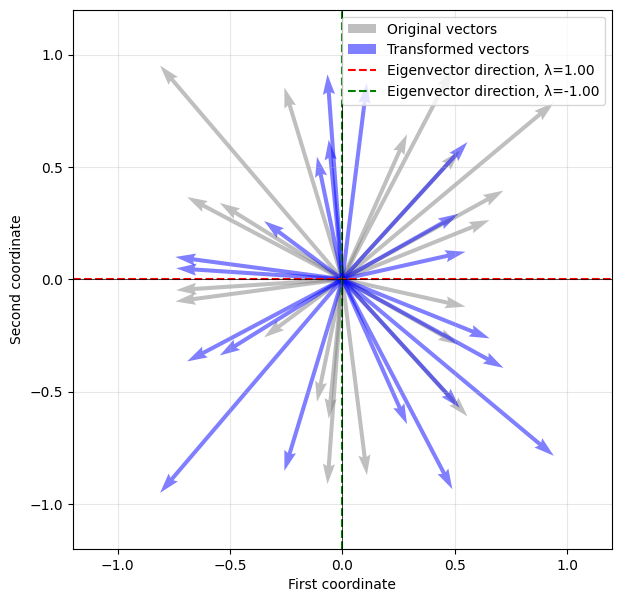

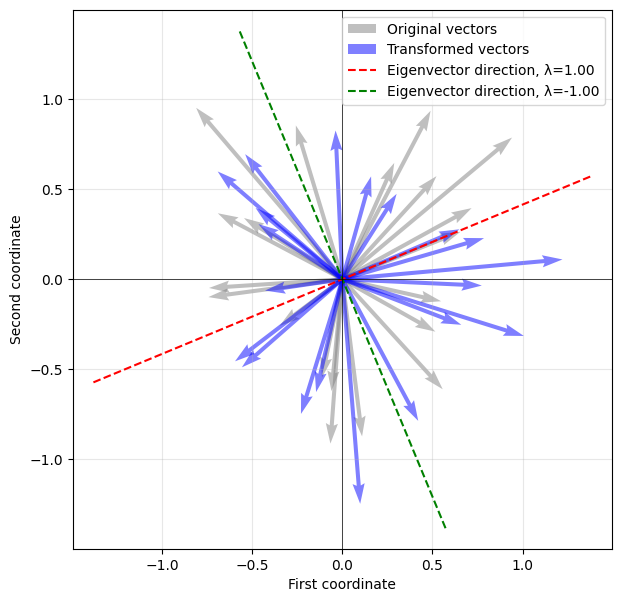

In [373]:
# TODO: test with some states

plot_gate_representation(np.array([[1, 0], [0, 1]]))
plot_gate_representation(np.array([[0, 1], [1, 0]]))
plot_gate_representation(X_gate())

Z = np.array([
    [1,  0],
    [0, -1],
], dtype=complex)
plot_gate_representation(Z)

plot_gate_representation(H_gate())

### 27. Represent state amplitudes

Write a function that receives a state (in computational basis) and draws a bar chart for the real and imaginary parts of each amplitude. Label each amplitude with its computational basis state.

In [375]:
def plot_state_amplitudes(state):
    state = np.asarray(state, dtype=complex)
    n_qubits = int(np.log2(len(state)))
    labels = [
        f"|{i:0{n_qubits}b}⟩"
        for i in range(len(state))
    ]

    x = np.arange(len(state))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - width / 2, state.real, width, label="Real")
    ax.bar(x + width / 2, state.imag, width, label="Imaginary")

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45)
    ax.set_xlabel("Computational basis state")
    ax.set_ylabel("Amplitude component")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()

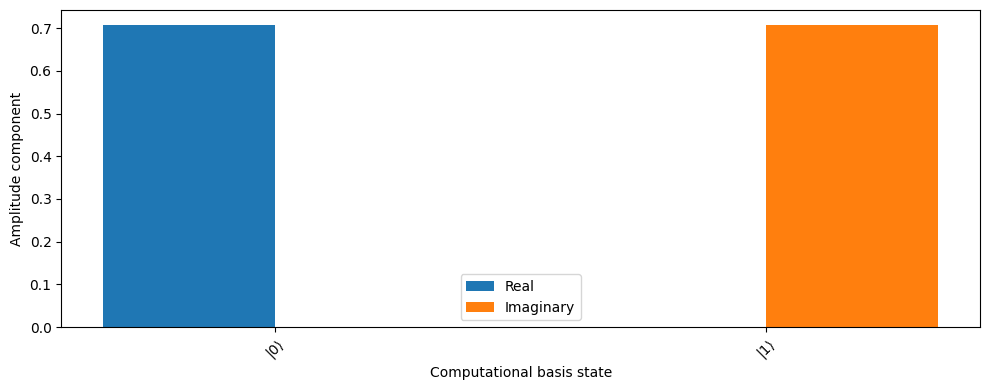

In [376]:
# TODO: test with some states

plot_state_amplitudes(np.array([1, 1j]) / np.sqrt(2))

## Conclusion
Congrats! You have done real quantum!